# 5. Preparação do Mapa de Uso e Cobertura da Terra

## 5.1 Introdução

Este notebook realiza a preparação do mapa de uso e cobertura da terra da Bacia Hidrográfica do Rio Doce. A partir do raster nacional do Projeto MapBiomas (Coleção 2, integração de uso e cobertura da terra, ano de 2023) e do limite da área de estudo previamente preparado, são executadas as etapas de carregamento, inspeção, recorte espacial, verificação dos valores presentes no raster, tratamento dos valores NoData, visualização e exportação do produto, gerando uma base padronizada para utilização nas análises ambientais das próximas etapas do projeto.

O raster nacional do MapBiomas cobre todo o território brasileiro e possui dimensões muito elevadas, o que inviabiliza sua leitura completa em memória em computadores pessoais. Para viabilizar o processamento sem comprometer a reprodutibilidade do fluxo de trabalho, o recorte é realizado inteiramente neste notebook a partir do arquivo original, utilizando a geometria da Bacia do Rio Doce por meio da função mask() da biblioteca Rasterio. O processamento evita a leitura integral do raster nacional e restringe a leitura à janela espacial da área de interesse; contudo, o recorte da bacia ainda possui grande dimensão e deve ser considerado no gerenciamento de memória.

Optou-se por não depender de um recorte prévio realizado em outro software (como o QGIS), de modo que todo o processamento — da leitura do dado bruto original até a exportação do produto final — fique documentado e reprodutível dentro deste notebook.

## 5.2 Objetivos

Ao final deste notebook será possível:

- carregar o raster nacional de uso e cobertura da terra do MapBiomas diretamente a partir do arquivo original;
- verificar a consistência dos dados raster;
- inspecionar o sistema de referência espacial e a resolução do raster;
- recortar o raster de uso e cobertura da terra utilizando o limite da Bacia do Rio Doce, com leitura otimizada por janela espacial para viabilizar o processamento do raster nacional em computadores pessoais;
- tratar os valores NoData;
- visualizar o resultado do processamento;
- exportar o raster para utilização nas próximas etapas do projeto.

## 5.3 Bibliotecas

In [1]:
from pathlib import Path
import geopandas as gpd
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from shapely.geometry import Point
from rasterio.mask import mask
from rasterio.enums import Resampling
from rasterio.plot import show
from rasterio.transform import xy

## 5.4 Estrutura dos Diretórios 

In [4]:
def encontrar_raiz_projeto():
    """Localiza a raiz do projeto a partir do diretório de execução."""
    inicio = Path.cwd().resolve()

    for pasta in (inicio, *inicio.parents):
        # Critério principal: diretório Git do repositório.
        if (pasta / ".git").exists():
            return pasta

        # Alternativa para cópias do projeto sem a pasta .git.
        if (
            (pasta / "README.md").is_file()
            and (pasta / "notebooks").is_dir()
            and (pasta / "dados").is_dir()
        ):
            return pasta

    raise FileNotFoundError(
        "Não foi possível localizar a raiz do projeto. "
        "Abra o Jupyter dentro do repositório Bacia_Rio_Doce."
    )


ROOT = encontrar_raiz_projeto()

In [5]:
DIR_DADOS = ROOT / "dados"
DIR_BRUTOS = DIR_DADOS / "brutos"
DIR_PROCESSADOS = DIR_DADOS / "processados"

DIR_MAPBIOMAS = DIR_BRUTOS / "UsoSolo"
DIR_ANA = DIR_BRUTOS / "ANA"
DIR_MAPBIOMAS_PROC = DIR_PROCESSADOS / "uso_solo"
DIR_AREA = DIR_PROCESSADOS / "area_estudo"

## 5.5 Dados de entrada

Arquivos utilizados

- mapbiomas_10m_collection2_2023.tif
- bacia_rio_doce.gpkg

Fontes

- Projeto MapBiomas
- Agência Nacional de Águas e Saneamento Básico (ANA)

Formatos

- GeoTIFF (TIF)
- GeoPackage (GPKG)

Sistema de referência esperado

- Uso e cobertura da terra (MapBiomas, raster nacional): EPSG:4326
- Área de estudo (bacia hidrográfica): EPSG:4674

## 5.6 Leitura

### Uso do Solo

In [6]:
INPUT_MAPBIOMAS = (
    DIR_MAPBIOMAS
    / "mapbiomas_10m_collection2_integration_v1-classification_2023.tif"
)

if not INPUT_MAPBIOMAS.is_file():
    raise FileNotFoundError(
        "Raster original do MapBiomas não encontrado. "
        f"Verifique se o arquivo está em: {INPUT_MAPBIOMAS.relative_to(ROOT)}"
    )

print(f"Arquivo MapBiomas: {INPUT_MAPBIOMAS.relative_to(ROOT)}")

Arquivo MapBiomas: dados\brutos\UsoSolo\mapbiomas_10m_collection2_integration_v1-classification_2023.tif


In [7]:
with rasterio.open(INPUT_MAPBIOMAS) as uso_cobertura:

    raster_crs = uso_cobertura.crs

    print(f"CRS: {uso_cobertura.crs}")
    print(f"Formato: {uso_cobertura.shape}")
    print(f"Resolução: {uso_cobertura.res}")
    print(f"Limites: {uso_cobertura.bounds}")
    print(f"Quantidade: {uso_cobertura.count}")
    print(f"Tipo de dado: {uso_cobertura.dtypes}")
    print(f"Pixels NoData: {uso_cobertura.nodata}")

CRS: EPSG:4326
Formato: (476412, 465718)
Resolução: (8.983152841195223e-05, 8.983152841195223e-05)
Limites: BoundingBox(left=-74.89739613957876, bottom=-34.852027909513524, right=-33.06123639062119, top=7.9447902042814595)
Quantidade: 1
Tipo de dado: ('uint8',)
Pixels NoData: None


O Projeto MapBiomas produz mapas anuais de uso e cobertura da terra para todo o território brasileiro utilizando séries temporais de imagens de satélite e técnicas de classificação automática. Esses dados permitem acompanhar a dinâmica da paisagem ao longo do tempo.

### Área de estudo

In [8]:
INPUT_AREA = DIR_AREA / "bacia_rio_doce.gpkg"

if not INPUT_AREA.is_file():
    raise FileNotFoundError(
        "Limite da bacia não encontrado. "
        f"Execute primeiro o Notebook 1 e verifique: {INPUT_AREA.relative_to(ROOT)}"
    )

print(f"Área de estudo: {INPUT_AREA.relative_to(ROOT)}")

Área de estudo: dados\processados\area_estudo\bacia_rio_doce.gpkg


In [9]:
bacia_rio_doce = gpd.read_file(INPUT_AREA)

C:\Users\claud\anaconda3\envs\AmbGEO\Lib\site-packages\pyogrio\core.py:34: RuntimeWarning: Could not detect GDAL data files. Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


In [10]:
print(f"Número de feições : {len(bacia_rio_doce)}")
print(f"CRS : {bacia_rio_doce.crs}")

Número de feições : 1
CRS : EPSG:4674


## 5.7 Processamento

### Reprojetar área de estudo

In [11]:
bacia_rio_doce = bacia_rio_doce.to_crs(raster_crs)

print(raster_crs)
print(bacia_rio_doce.crs)

EPSG:4326
GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]


### Recorte espacial

In [12]:
with rasterio.open(INPUT_MAPBIOMAS) as uso_cobertura:

    mapbiomas_recortado, transform = mask(
        uso_cobertura,
        bacia_rio_doce.geometry,
        crop=True,
        filled=False,
        all_touched=False 
    )

In [13]:
print("Original:", uso_cobertura.shape)
print("Recortado:", mapbiomas_recortado.shape)

Original: (476412, 465718)
Recortado: (1, 38111, 46072)


### Verificação dos valores (classes e possíveis NoData internos)

O raster original do MapBiomas não possui um valor de NoData definido nos metadados (ver seção 5.6). Nesse produto, o valor 0 representa pixels sem classificação, que podem ocorrer tanto fora do território brasileiro quanto dentro dele (por exemplo, áreas persistentemente encobertas por nuvens). A verificação abaixo lista as classes presentes dentro da Bacia do Rio Doce e a quantidade de pixels de cada uma, permitindo avaliar se a classe 0 deve ser tratada como um valor adicional de NoData antes da exportação (seção 5.9).

In [14]:
valores, contagem = np.unique(mapbiomas_recortado.compressed(), return_counts=True)

distribuicao_classes = dict(zip(valores.tolist(), contagem.tolist()))
distribuicao_classes

{0: 50,
 3: 237851249,
 4: 10688703,
 5: 27,
 9: 62473211,
 11: 1490742,
 12: 2394314,
 15: 414785297,
 19: 764200,
 21: 144724216,
 23: 596459,
 24: 6663914,
 25: 1426877,
 29: 14851857,
 30: 1745108,
 31: 3205,
 33: 7498356,
 36: 8538376,
 49: 506982,
 50: 796366}

## 5.8 Visualização

### Área de estudo sobre o MapBiomas

Como o raster do MapBiomas possui dimensões muito grandes, é utilizada uma versão reduzida apenas para inspeção visual. O reamostramento pelo método do vizinho mais próximo (nearest) preserva os códigos originais das classes de uso e cobertura da terra, evitando a criação de valores intermediários que poderiam comprometer a interpretação dos dados. O raster original permanece inalterado e será utilizado nas etapas de processamento e exportação.

In [15]:
with rasterio.open(INPUT_MAPBIOMAS) as uso_cobertura:

    fator = 50

    preview = uso_cobertura.read(
        1,
        out_shape=(
            uso_cobertura.height // fator,
            uso_cobertura.width // fator
        ),
        resampling=Resampling.nearest
    )

    preview_transform = uso_cobertura.transform * uso_cobertura.transform.scale(
        uso_cobertura.width / preview.shape[1],
        uso_cobertura.height / preview.shape[0]
    )

C:\Users\claud\AppData\Local\Temp\ipykernel_6272\453074298.py:5: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  preview = uso_cobertura.read(


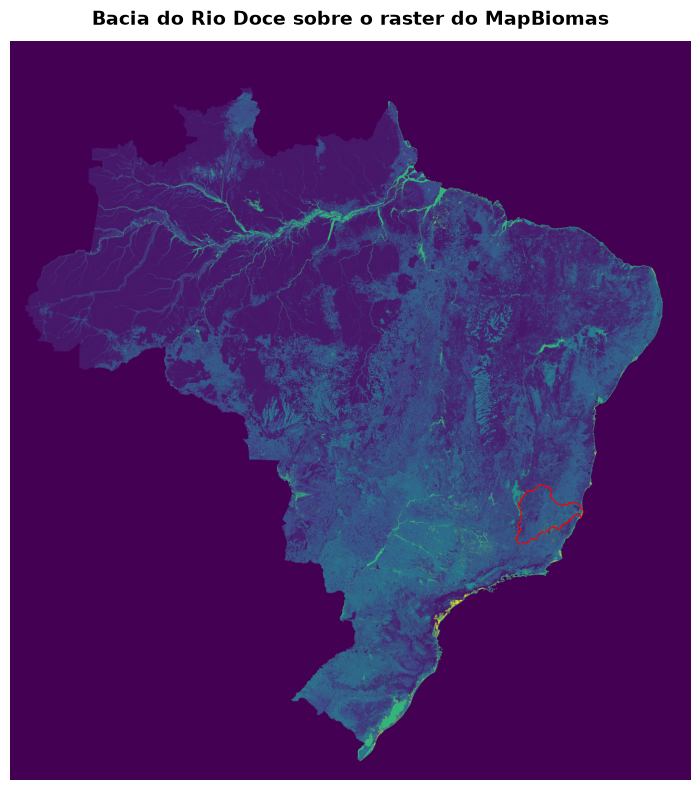

In [16]:
fig, ax = plt.subplots(figsize=(8, 8))

show(
    preview,
    transform=preview_transform,
    ax=ax
)

bacia_rio_doce.boundary.plot(
    ax=ax,
    edgecolor="red",
    linewidth=0.5
)

ax.set_title(
    "Bacia do Rio Doce sobre o raster do MapBiomas",
    fontsize=14,
    fontweight="bold",
    pad=12
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

- O recorte espacial reduz significativamente o volume de dados a ser processado e garante que todas as análises subsequentes 
sejam realizadas apenas dentro da área de estudo.
- O raster não possui valor NoData definido nos metadados.
- A conversão para float apenas permiti a utilização de NaN na visualização.
- Neste produto, o valor 0 representa pixels sem classificação.

### Raster MapBiomas recortado

In [17]:
fator = 10

preview_recorte = mapbiomas_recortado[0][
    ::fator,
    ::fator
].copy()

preview_transform = transform * transform.scale(
    fator,
    fator
)

In [18]:
cmap = plt.cm.viridis.copy()
cmap.set_bad("white")

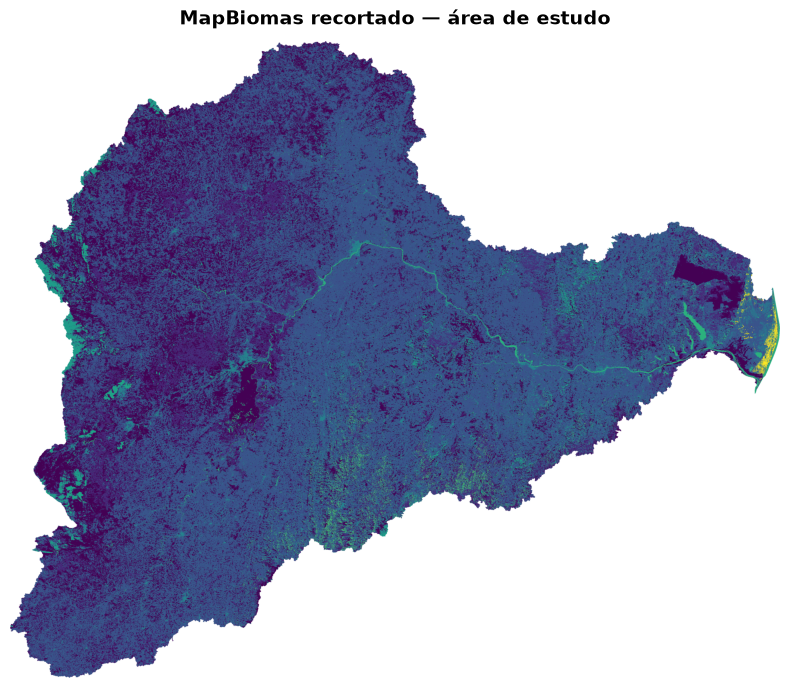

In [19]:
fig, ax = plt.subplots(figsize=(8, 8))

show(
    preview_recorte,
    transform=preview_transform,
    ax=ax,
    cmap=cmap
)

ax.set_title(
    "MapBiomas recortado — área de estudo",
    fontsize=14,
    fontweight="bold",
    pad=12
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

A paleta viridis é utilizada apenas para inspeção visual do raster. As cores oficiais do MapBiomas serão utilizadas nas análises temáticas de uso e cobertura da terra.

## 5.9 Explorar a classe 0

In [20]:
# Localiza os pixels da classe 0
mascara_valida = ~mapbiomas_recortado[0].mask
mascara_classe_0 = (mapbiomas_recortado[0].data == 0) & mascara_valida

# Índices de linha e coluna dos pixels
linhas, colunas = np.where(mascara_classe_0)

print(f"Número de pixels da classe 0: {len(linhas)}")

Número de pixels da classe 0: 50


In [21]:
coordenadas = [
    xy(transform, linha, coluna)
    for linha, coluna in zip(linhas, colunas)
]

coordenadas[:10]

[(np.float64(-42.99898396848603), np.float64(-18.13487454545548)),
 (np.float64(-43.15645863779218), np.float64(-18.144845845109206)),
 (np.float64(-43.15798577377518), np.float64(-18.146642475677446)),
 (np.float64(-43.159512909758185), np.float64(-18.148439106245686)),
 (np.float64(-43.16104004574119), np.float64(-18.150235736813926)),
 (np.float64(-43.166879095087964), np.float64(-18.159578215768768)),
 (np.float64(-43.16732825273002), np.float64(-18.160296867996063)),
 (np.float64(-43.17900635142358), np.float64(-18.176915700752275)),
 (np.float64(-43.280605810057494), np.float64(-18.34346335442803)),
 (np.float64(-43.280875304642734), np.float64(-18.345439648053095))]

In [22]:
pontos_classe_0 = gpd.GeoDataFrame(
    {"classe": [0] * len(coordenadas)},
    geometry=[
        Point(x, y)
        for x, y in coordenadas
    ],
    crs=uso_cobertura.crs
)

pontos_classe_0

,classe,geometry
0,0,POINT (-42.99898 -18.13487)
1,0,POINT (-43.15646 -18.14485)
2,0,POINT (-43.15799 -18.14664)
3,0,POINT (-43.15951 -18.14844)
4,0,POINT (-43.16104 -18.15024)
5,0,POINT (-43.16688 -18.15958)
6,0,POINT (-43.16733 -18.1603)
7,0,POINT (-43.17901 -18.17692)
8,0,POINT (-43.28061 -18.34346)
9,0,POINT (-43.28088 -18.34544)


In [23]:
print(pontos_classe_0[["geometry"]].to_string())

                       geometry
0   POINT (-42.99898 -18.13487)
1   POINT (-43.15646 -18.14485)
2   POINT (-43.15799 -18.14664)
3   POINT (-43.15951 -18.14844)
4   POINT (-43.16104 -18.15024)
5   POINT (-43.16688 -18.15958)
6    POINT (-43.16733 -18.1603)
7   POINT (-43.17901 -18.17692)
8   POINT (-43.28061 -18.34346)
9   POINT (-43.28088 -18.34544)
10  POINT (-43.42613 -18.51163)
11  POINT (-43.43772 -18.57379)
12  POINT (-43.47599 -18.59715)
13   POINT (-43.4706 -18.61179)
14  POINT (-43.46772 -18.61475)
15  POINT (-43.47123 -18.65976)
16  POINT (-43.49036 -18.66749)
17  POINT (-43.63337 -18.95989)
18  POINT (-43.63275 -18.96088)
19   POINT (-43.62897 -18.9668)
20  POINT (-43.62601 -18.97148)
21  POINT (-43.62538 -18.97246)
22  POINT (-43.62241 -18.97713)
23  POINT (-43.62098 -18.97938)
24   POINT (-43.62053 -18.9801)
25   POINT (-43.6199 -18.98109)
26  POINT (-43.61945 -18.98181)
27  POINT (-43.61927 -18.98208)
28  POINT (-43.61882 -18.98279)
29  POINT (-43.61864 -18.98306)
30  POIN

In [24]:
for i, ponto in enumerate(pontos_classe_0.geometry):
    print(i, ponto.x, ponto.y)

0 -42.99898396848603 -18.13487454545548
1 -43.15645863779218 -18.144845845109206
2 -43.15798577377518 -18.146642475677446
3 -43.159512909758185 -18.148439106245686
4 -43.16104004574119 -18.150235736813926
5 -43.166879095087964 -18.159578215768768
6 -43.16732825273002 -18.160296867996063
7 -43.17900635142358 -18.176915700752275
8 -43.280605810057494 -18.34346335442803
9 -43.280875304642734 -18.345439648053095
10 -43.42613288608486 -18.51162797561521
11 -43.43772115325 -18.573791393276277
12 -43.47598938435349 -18.597147590663386
13 -43.47059949264877 -18.611790129794535
14 -43.46772488373959 -18.61475457023213
15 -43.47122831334766 -18.659760165966517
16 -43.4903624288994 -18.667485677409946
17 -43.63337422213123 -18.95988730239085
18 -43.63274540143235 -18.96087544920338
19 -43.628972477239046 -18.96680433007857
20 -43.62600803680145 -18.97147556955599
21 -43.62537921610257 -18.972463716368523
22 -43.62241477566498 -18.977134955845944
23 -43.62097747121038 -18.979380744056243
24 -43.62

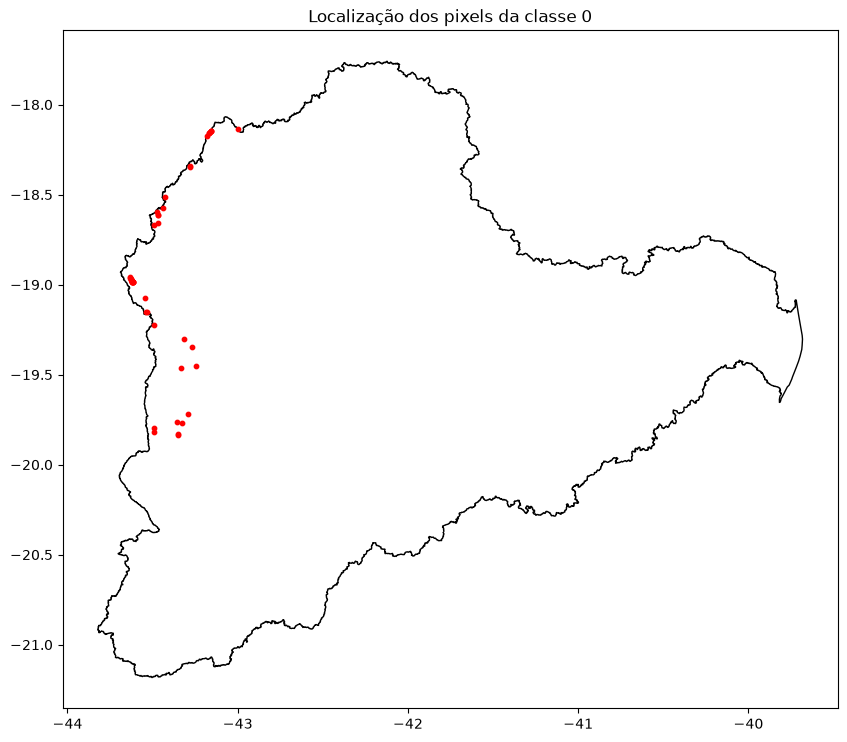

In [25]:
fig, ax = plt.subplots(figsize=(10, 10))

bacia_rio_doce.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black"
)

pontos_classe_0.plot(
    ax=ax,
    color="red",
    markersize=10
)

ax.set_title("Localização dos pixels da classe 0")
plt.show()

#### Conclusão
Os 50 pixels de valor 0 correspondem a 0,0000054% da área da bacia — um volume estatisticamente irrelevante para qualquer análise futura. O valor 0 não corresponde a nenhuma classe da legenda oficial do MapBiomas (a classe reservada para "não observado" é a 27, que sequer aparece neste recorte); trata-se de um valor de preenchimento (background) do raster, e não de uma decisão do classificador. Por não ser uma classe interpretável e por sua proporção ser desprezível, a classe 0 será tratada como um valor adicional de NoData, unida ao valor 255 já definido para os pixels fora da bacia (seção 5.10).

In [26]:
# Unir a classe 0 ao NoData já existente (pixels fora da bacia)
# mascara_classe_0 foi definida na verificação acima e já considera apenas pixels válidos
mapbiomas_recortado.mask = mapbiomas_recortado.mask | mascara_classe_0[np.newaxis, :, :]

In [27]:
# Conferir que a classe 0 não aparece mais entre os valores válidos
valores, contagem = np.unique(mapbiomas_recortado.compressed(), return_counts=True)
dict(zip(valores.tolist(), contagem.tolist()))

{3: 237851249,
 4: 10688703,
 5: 27,
 9: 62473211,
 11: 1490742,
 12: 2394314,
 15: 414785297,
 19: 764200,
 21: 144724216,
 23: 596459,
 24: 6663914,
 25: 1426877,
 29: 14851857,
 30: 1745108,
 31: 3205,
 33: 7498356,
 36: 8538376,
 49: 506982,
 50: 796366}

## 5.10 Preparar o perfil do raster e exportação

In [28]:
with rasterio.open(INPUT_MAPBIOMAS) as uso_cobertura:

    perfil = uso_cobertura.profile.copy()

perfil.update({
    "height": mapbiomas_recortado.shape[1],
    "width": mapbiomas_recortado.shape[2],
    "transform": transform
})

In [29]:
OUTPUT_MAPBIOMAS = DIR_MAPBIOMAS_PROC / "mapbiomas_bacia_rio_doce.tif"

# Garante que a pasta de saída exista antes da exportação.
DIR_MAPBIOMAS_PROC.mkdir(parents=True, exist_ok=True)

In [30]:
# Definir NoData e otimizar a gravação do arquivo processado
perfil.update({
    "nodata": 255,
    "compress": "deflate",
    "predictor": 2,
    "tiled": True,
    "blockxsize": 256,
    "blockysize": 256,
})

## 5.11 Salvar o raster processado

In [32]:
with rasterio.open(
    OUTPUT_MAPBIOMAS,
    "w",
    **perfil
) as dst:

    dst.write(
        mapbiomas_recortado.filled(255)
    )

Caminho de saída: dados\processados\uso_solo\mapbiomas_bacia_rio_doce.tif


### Verificar o arquivo gerado

In [33]:
with rasterio.open(OUTPUT_MAPBIOMAS) as mapbiomas_ds:

    print("CRS:", mapbiomas_ds.crs)
    print("Dimensões:", mapbiomas_ds.height, "x", mapbiomas_ds.width)
    print("Resolução:", mapbiomas_ds.res)
    print("Bandas:", mapbiomas_ds.count)
    print("Tipo:", mapbiomas_ds.dtypes)
    print("NoData:", mapbiomas_ds.nodata)

print("\nArquivo salvo em:")
print(OUTPUT_MAPBIOMAS.relative_to(ROOT))
print("\nProcessamento concluído.")

CRS: EPSG:4326
Dimensões: 38111 x 46072
Resolução: (8.983152841195223e-05, 8.983152841195223e-05)
Bandas: 1
Tipo: ('uint8',)
NoData: 255.0

Arquivo salvo em:
dados\processados\uso_solo\mapbiomas_bacia_rio_doce.tif

Processamento concluído.


### Liberação da memória

In [34]:
del mapbiomas_recortado
del preview_recorte

In [35]:
import gc
gc.collect()

5185

## 5.12 Conclusão Final

Neste notebook foi preparado o mapa de uso e cobertura da terra da Bacia Hidrográfica do Rio Doce. O raster do MapBiomas foi carregado, inspecionado, recortado utilizando o limite da área de estudo, teve seus valores NoData tratados e foi exportado em formato GeoTIFF.              
O raster exportado constitui a base para as análises de uso e cobertura da terra desenvolvidas nas próximas etapas do projeto, permitindo sua integração com informações de relevo, hidrografia, solos e áreas de preservação permanente.